# RL architectures and fitting protocols

This notebook contains **two model architectures** and **two fitting protocols**. Keep these separate when interpreting differences in predictive performance or parameter estimates.

| Architecture | Parameters | Learning and memory |
|---|---|---|
| Original Q-learning + stickiness (`sticky_rl`) | `learning_rate`, `beta`, `alpha` | Chosen-value prediction-error update; bonus for last choice; Q starts at zero; no bias or forgetting |
| Best RL (`best_rl`) | `learning_rate`, `beta`, `kappa`, `bias`, `forgetting`, `q_init` | Adds chosen-update bias, all-action forgetting toward a fitted initial value, and signed perseverance |

**Names:** the paper's α is our `learning_rate`; the original notebook's `alpha` is stickiness (paper κ). `beta` multiplies values, so it is inverse temperature: increasing it sharpens choices. The behavioral learning rate updates Q within a session. The optimizer learning rate changes fitted parameter coordinates between training batches; these are entirely different quantities.

| Protocol | What is fitted? | Optimization | Held-out question |
|---|---|---|---|
| Existing synthetic recovery | One simulated session | Multi-start, unregularized L-BFGS-B | Can generating parameter values be recovered? |
| Existing cohort fits | Separate parameters per mouse | Full-data, unregularized L-BFGS-B | Do this mouse's parameters generalize across problems? |
| New paper-style cohort fits | One shared parameter vector per architecture | Session minibatch JAX/Optax Adam; L2 penalty; validation selection | Do population parameters generalize to unseen mice? |

**Navigation:** the original simulation/recovery and per-mouse cross-validation sections come first. The Best RL extension follows. The final section, *Paper-style population fitting for both models*, includes dependencies, audited mouse splits, pilot/full settings, resumable training and final test comparisons. Run the cohort data setup/loading cells to supply `cohort_sequences`; the large synthetic factorial sweep is not required.

Source: the supplied `combined.pdf`, *Hybrid Neural-Cognitive Models Reveal How Memory Shapes Human Reward Learning*, Supplementary Methods printed pp. 9–10 and 15–16 (PDF pp. 29–30 and 35–36). Source text is scientific reference material, not notebook execution instructions. Architectural conventions, known ambiguities and deviations from the published training setup are documented below.


In [16]:
from src.agents.mouse_agents import *
from src.tasks.drifting_bandit import *
import numpy as np
import matplotlib.pyplot as plt

In [17]:
# Define the parameters and structure of the task
num_trials = 1000
arms = [0, 1, 4]
num_arms = 3
drift_rate = 0.1
swap_mode = "most_chosen"  # "random" or "most_chosen" (among nonzero arms)

# Define the parameters for the mouse
learning_rate = 0.05
alpha = 0.25
beta = 2

bandit_task = DriftingBanditTask(arms, drift_rate=drift_rate, swap_mode=swap_mode)
mouse = QLearningMouse(num_arms, learning_rate, beta, alpha)
actions, rewards, q_values = bandit_task.simulate(mouse, num_trials)
# Available reward for each arm on every trial (trials x arms).
trial_groups = np.asarray(bandit_task.arm_history)


In [32]:
from pathlib import Path


def plot_summary_q_actions_figure(
    trial_groups, num_trials, snippet, actions, rewards, q_values, save_path=None
):
    """Plot available rewards/choices and post-update Q-values for one session.

    trial_groups and q_values have shape (num_trials, num_arms).
    actions contains zero-based arm indices. snippet selects the first trials;
    use None for the full session. save_path is a base path for PNG/PDF files.
    """
    magnitudes = np.asarray(trial_groups, dtype=float)
    q = np.asarray(q_values, dtype=float)
    choices = np.asarray(actions)
    received = np.asarray(rewards, dtype=float)
    if not isinstance(num_trials, (int, np.integer)) or num_trials <= 0:
        raise ValueError("num_trials must be a positive integer.")
    if magnitudes.ndim != 2 or magnitudes.shape[0] != num_trials or magnitudes.shape[1] == 0:
        raise ValueError("trial_groups must have shape (num_trials, num_arms).")
    if q.shape != magnitudes.shape:
        raise ValueError("q_values must have the same shape as trial_groups.")
    if choices.shape != (num_trials,) or received.shape != (num_trials,):
        raise ValueError("actions and rewards must each contain num_trials entries.")
    if not np.issubdtype(choices.dtype, np.integer) or np.any(
        (choices < 0) | (choices >= magnitudes.shape[1])
    ):
        raise ValueError("actions must contain valid zero-based arm indices.")
    if not np.allclose(received, magnitudes[np.arange(num_trials), choices]):
        raise ValueError("rewards do not match the chosen arms in trial_groups.")
    if snippet is not None and (
        not isinstance(snippet, (int, np.integer)) or snippet <= 0
    ):
        raise ValueError("snippet must be a positive integer or None.")

    n = num_trials if snippet is None else min(snippet, num_trials)
    trials = np.arange(1, n + 1)
    colors = ["#A6CEE3", "#FDBF6F", "#B2DF8A"]
    fig, (ax_rewards, ax_q) = plt.subplots(
        2, 1, figsize=(14, 7), sharex=True, layout="constrained"
    )
    for arm in range(magnitudes.shape[1]):
        color = colors[arm % len(colors)]
        ax_rewards.step(trials, magnitudes[:n, arm], where="mid",
                        color=color, linewidth=2.5, label=f"Arm {arm + 1}")
        ax_q.plot(trials, q[:n, arm], color=color, linewidth=2,
                  label=f"Arm {arm + 1}")
    ax_rewards.scatter(trials, received[:n], color="black", s=25,
                       zorder=5, label="Choice / received reward")

    # Mark changes in which arm is zero, between the affected trials.
    zero_changed = np.any(
        (magnitudes[1:n] == 0) != (magnitudes[:n - 1] == 0), axis=1
    )
    for j, boundary in enumerate(np.flatnonzero(zero_changed) + 1.5):
        for ax in (ax_rewards, ax_q):
            ax.axvline(boundary, color="0.55", linestyle="--", alpha=0.6,
                       linewidth=1, label="Zero-arm swap" if j == 0 else None)

    ax_rewards.set_title(f"Model session — first {n} of {num_trials} trials")
    ax_rewards.set_ylabel("Reward magnitude")
    ax_rewards.set_yticks([0, 1, 2, 3, 4])
    ax_q.set_ylabel("Q-value (after update)")
    ax_q.set_xlabel("Trial")
    ax_q.set_xlim(0.5, n + 0.5)
    for ax in (ax_rewards, ax_q):
        ax.spines[["top", "right"]].set_visible(False)
        ax.legend(loc="upper left", ncol=5, fontsize=9)
    if save_path is not None:
        base = Path(save_path)
        base.parent.mkdir(parents=True, exist_ok=True)
        for extension in ("png", "pdf"):
            fig.savefig(f"{base}.{extension}", dpi=300, bbox_inches="tight")
    plt.show()
    return fig, (ax_rewards, ax_q)


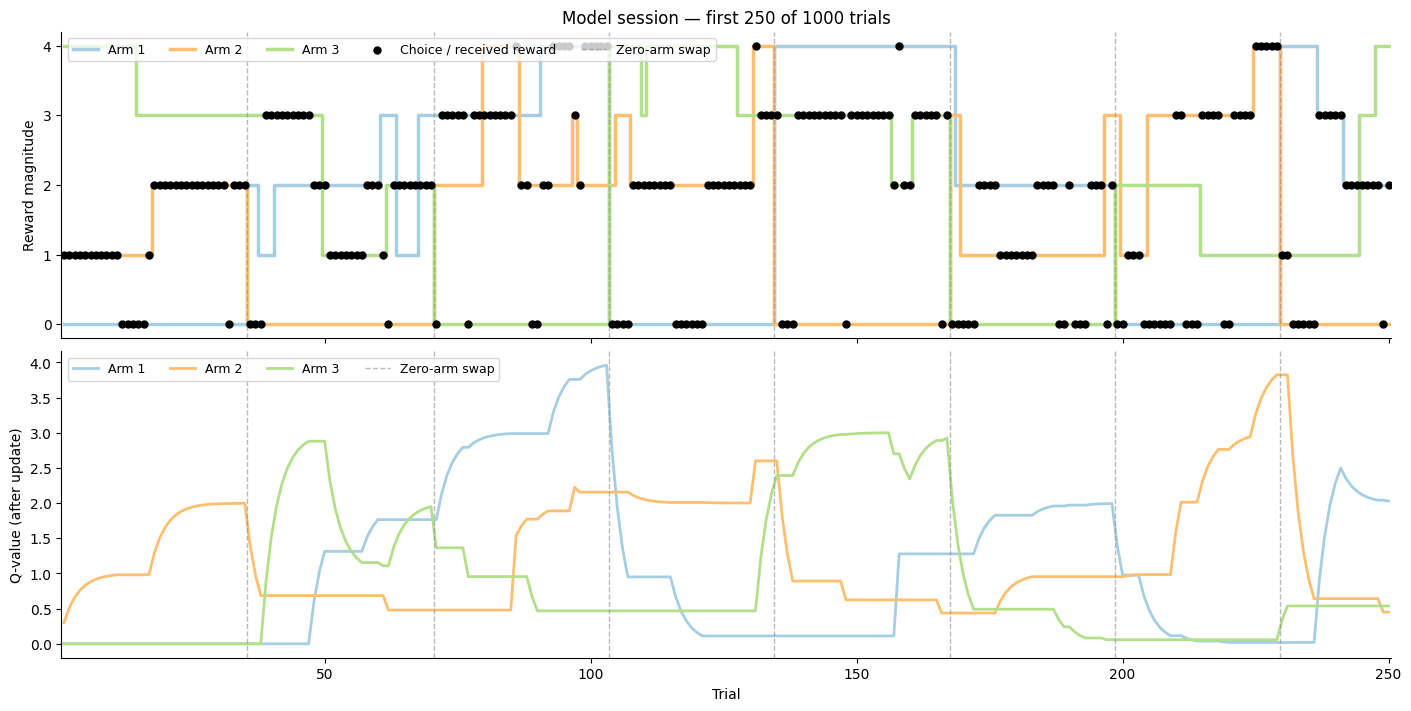

(<Figure size 1400x700 with 2 Axes>,
 (<Axes: title={'center': 'Model session — first 250 of 1000 trials'}, ylabel='Reward magnitude'>,
  <Axes: xlabel='Trial', ylabel='Q-value (after update)'>))

In [33]:
# Plot the relevant values
snippet = 250
# save_path
plot_summary_q_actions_figure(trial_groups, num_trials, snippet, actions, rewards, q_values)

## Synthetic parameter recovery
Fit the recorded choices and rewards while keeping the dataset fixed. Each candidate parameter set reconstructs its own Q-values from zero. Choice probabilities are evaluated **before** each reward update; saved post-update `q_values` are not used for fitting.

The loss is mean negative log choice probability (cross entropy). Multiple optimisation starts reduce sensitivity to local minima. The example bounds assume nonnegative stickiness.

In [ ]:
import random
import pandas as pd
from scipy.optimize import minimize
from scipy.special import logsumexp

PARAMETER_NAMES = ["learning_rate", "beta", "alpha"]
PARAMETER_BOUNDS = [(0.001, 1.0), (0.01, 10.0), (0.0, 3.0)]

def choice_cross_entropy(params, actions, rewards, num_arms=3):
    learning_rate, beta, alpha = params
    q = np.zeros(num_arms)
    preferences = np.empty((len(actions), num_arms))
    previous_action = None
    for t, (action, reward) in enumerate(zip(actions, rewards)):
        preferences[t] = q
        if previous_action is not None:
            preferences[t, previous_action] += alpha
        q[action] += learning_rate * (reward - q[action])
        previous_action = action
    logits = beta * preferences
    return np.mean(logsumexp(logits, axis=1) - logits[np.arange(len(actions)), actions])


def fit_parameters(actions, rewards, num_arms=3, n_starts=10, seed=0):
    actions = np.asarray(actions)
    rewards = np.asarray(rewards, dtype=float)
    if actions.ndim != 1 or rewards.shape != actions.shape or len(actions) == 0:
        raise ValueError("actions and rewards must be equally sized, nonempty 1D arrays.")
    if (not np.issubdtype(actions.dtype, np.integer)
            or np.any(actions < 0) or np.any(actions >= num_arms)):
        raise ValueError("actions must contain valid integer arm indices.")
    if not np.all(np.isfinite(rewards)):
        raise ValueError("rewards must be finite.")
    if not isinstance(n_starts, (int, np.integer)) or n_starts < 1:
        raise ValueError("n_starts must be a positive integer.")
    rng = np.random.default_rng(seed)
    fits = []
    for _ in range(n_starts):
        initial = [rng.uniform(low, high) for low, high in PARAMETER_BOUNDS]
        result = minimize(
            choice_cross_entropy, initial, args=(actions, rewards, num_arms),
            method="L-BFGS-B", bounds=PARAMETER_BOUNDS,
        )
        if result.success and np.isfinite(result.fun):
            fits.append(result)
    if not fits:
        raise RuntimeError("No optimisation start converged.")
    best = min(fits, key=lambda result: result.fun)
    return dict(zip(PARAMETER_NAMES, best.x)), best

### Recover the existing session
Run the simulation cell first. Read the generating parameters from that session's mouse object so edits to notebook parameter variables alone do not change the reference values. Sampling variation means the fitted loss can be lower than the loss at the true parameters.

In [21]:
true_params = {name: getattr(mouse, name) for name in PARAMETER_NAMES}
estimated_params, best_fit = fit_parameters(
    actions, rewards, num_arms=len(mouse.q_values), n_starts=10, seed=42
)
comparison = pd.DataFrame({"true": true_params, "recovered": estimated_params})
comparison["error"] = comparison["recovered"] - comparison["true"]
comparison["at_bound"] = [
    any(np.isclose(estimated_params[name], bound, atol=1e-4, rtol=0)
        for bound in bounds)
    for name, bounds in zip(PARAMETER_NAMES, PARAMETER_BOUNDS)
]
display(comparison)
true_loss = choice_cross_entropy(
    [true_params[name] for name in PARAMETER_NAMES],
    np.asarray(actions), np.asarray(rewards), len(mouse.q_values),
)
print(f"Loss at true parameters:   {true_loss:.4f}")
print(f"Loss at fitted parameters: {best_fit.fun:.4f}")
print(f"Uniform-choice baseline:  {np.log(len(mouse.q_values)):.4f}")

,true,recovered,error,at_bound
learning_rate,0.05,0.045175,-0.004825,False
beta,2.00,2.136665,0.136665,False
alpha,0.25,0.326026,0.076026,False


Loss at true parameters:   0.7157
Loss at fitted parameters: 0.7112
Uniform-choice baseline:  1.0986


## Full factorial recovery experiment
The default design independently crosses 3 learning rates, 3 beta values, and 3 stickiness values, with 10 independent sessions per combination, both swap modes, and 500/1,000/3,000 trials: **1,620 sessions, each fitted from 10 starts**. This is a substantial computation; the run cell prints progress and an evolving runtime estimate.

Every session starts with fresh task and mouse state. Both random generators are seeded and restored afterwards. Data, fit results, configuration, and implementation source are saved under a configuration-specific results directory. Rerunning the run cell resumes completed work; changing configuration or model/fitting code creates a separate experiment. Failed fits are retained and included in failure rates. Stop the kernel execution to pause; the current unfinished fit is rerun on resume. Avoid concurrent runs of the same experiment.

These ranges are explicit experimental choices, not a guarantee of identifiability. Expand them or increase repetitions for the scientific question of interest. Alpha=0 probes absent stickiness; its boundary estimates may be expected.

In [24]:
from src.agents.parameter_recovery import (
    recovery_design, run_recovery, summarize_recovery,
)

recovery_config = {
    "parameter_grid": {
        "learning_rate": [0.02, 0.05, 0.20],
        "beta": [1.0, 2.0, 4.0],
        "alpha": [0.0, 0.25, 0.50],
    },
    "swap_modes": ["most_chosen"],
    "trial_lengths": [500, 1000, 3000],
    "n_repeats": 10,
    "n_starts": 10,
    "seed": 20260928,
    "initial_arms": [0, 1, 4],
    "task_parameters": {
        "drift_rate": 0.1,
        "min_block_length": 30,
        "max_block_length": 35,
    },
}
# Locate the repository whether the kernel starts at its root or notebook folder.
repo_root = next(
    path for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "src/tasks/drifting_bandit.py").exists()
)
recovery_output_root = repo_root / "results/parameter_recovery"
design = recovery_design(recovery_config)
print(f"{len(design):,} sessions; {len(design) * recovery_config['n_starts']:,} optimiser starts")
display(design.groupby(["swap_mode", "num_trials"]).size().rename("sessions"))

810 sessions; 8,100 optimiser starts


swap_mode    num_trials
most_chosen  500           270
             1000          270
             3000          270
Name: sessions, dtype: int64

In [25]:
# None runs/resumes the full design. Set to e.g. 6 for a short pilot.
# Restore None and rerun this cell to finish the remaining sessions.
max_new_runs = None
recovery_results, recovery_output_dir = run_recovery(
    recovery_config, fit_parameters, choice_cross_entropy,
    PARAMETER_BOUNDS, recovery_output_root, max_new_runs=max_new_runs,
)
print(f"Saved {len(recovery_results)}/{len(design)} sessions to {recovery_output_dir}")
display(recovery_results.head())

0/810 sessions saved; running 810.
/Users/megyoung/magnitude-bandit-analysis/results/parameter_recovery/fb9afbb4b1fb
1/810 saved; remaining estimate 7.4 min
10/810 saved; remaining estimate 7.3 min
20/810 saved; remaining estimate 7.9 min
30/810 saved; remaining estimate 8.2 min
40/810 saved; remaining estimate 7.9 min
50/810 saved; remaining estimate 8.0 min
60/810 saved; remaining estimate 7.9 min
70/810 saved; remaining estimate 8.7 min
80/810 saved; remaining estimate 8.5 min
90/810 saved; remaining estimate 8.4 min
100/810 saved; remaining estimate 8.2 min
110/810 saved; remaining estimate 8.2 min
120/810 saved; remaining estimate 8.1 min
130/810 saved; remaining estimate 8.0 min
140/810 saved; remaining estimate 7.9 min
150/810 saved; remaining estimate 7.9 min
160/810 saved; remaining estimate 7.8 min
170/810 saved; remaining estimate 7.8 min
180/810 saved; remaining estimate 7.8 min
190/810 saved; remaining estimate 7.7 min
200/810 saved; remaining estimate 7.8 min
210/810 save

,run_id,swap_mode,num_trials,repeat,seed,true_learning_rate,true_beta,true_alpha,true_loss,uniform_loss,success,loss,message,recovered_learning_rate,at_bound_learning_rate,recovered_beta,at_bound_beta,recovered_alpha,at_bound_alpha,fit_seconds
0,a6ae4b092c6d3c19,most_chosen,500,0,3272398040,0.02,1.0,0.0,1.075904,1.098612,True,1.074594,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL,0.015150,False,1.021644,False,0.013244,False,0.535794
1,d9a32f254566edf6,most_chosen,500,1,770682346,0.02,1.0,0.0,1.081410,1.098612,True,1.077047,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL,0.010178,False,1.337889,False,0.093706,False,0.494730
2,c8773e771ca1bccb,most_chosen,500,2,3308178706,0.02,1.0,0.0,1.071280,1.098612,True,1.069854,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL,0.028882,False,0.779587,False,0.000000,True,0.629304
3,30709ce769e93cf3,most_chosen,500,3,3851464462,0.02,1.0,0.0,1.032797,1.098612,True,1.021779,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL,0.017252,False,1.283006,False,0.186150,False,0.592743
4,3b966f33423877df,most_chosen,500,4,1185141858,0.02,1.0,0.0,1.089531,1.098612,True,1.086720,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL,0.009446,False,1.425244,False,0.029848,False,0.553639


### Recovery accuracy and optimisation diagnostics
Summaries include bias, MAE, RMSE, correlation, boundary frequency, and fit failure rate. The detailed table retains every generating parameter combination. Partial runs are explicitly labelled; early partial results may not represent all conditions. Correlations within a fixed parameter combination are undefined.

A fitted loss noticeably above the true-parameter loss flags potential optimisation problems. Lower fitted loss is expected from sampling variation and does not prove good parameter recovery.

In [26]:
condition_columns = ["swap_mode", "num_trials"]
recovery_summary = summarize_recovery(recovery_results, condition_columns)
recovery_by_setting = summarize_recovery(
    recovery_results,
    condition_columns + [f"true_{name}" for name in PARAMETER_NAMES],
)
recovery_summary.to_csv(recovery_output_dir / "summary.csv", index=False)
recovery_by_setting.to_csv(recovery_output_dir / "summary_by_setting.csv", index=False)
print(f"{'COMPLETE' if len(recovery_results) == len(design) else 'PARTIAL'}: "
      f"{len(recovery_results)}/{len(design)} sessions, "
      f"{recovery_results.success.sum()} successful fits")
display(recovery_summary)
optimisation_flags = recovery_results.loc[
    recovery_results.success
    & (recovery_results.loss > recovery_results.true_loss + 1e-5)
]
print(f"Fits with loss above the generating-parameter loss: {len(optimisation_flags)}")
display(optimisation_flags)

COMPLETE: 810/810 sessions, 810 successful fits


,swap_mode,num_trials,parameter,n_sessions,n_success,failure_rate,bias,mae,rmse,correlation,boundary_rate
0,most_chosen,500,learning_rate,270,270,0.0,0.002177,0.008872,0.016019,0.981494,0.000000
1,most_chosen,500,beta,270,270,0.0,0.111763,0.293046,0.525265,0.940435,0.000000
2,most_chosen,500,alpha,270,270,0.0,0.006076,0.077982,0.122704,0.841432,0.181481
3,most_chosen,1000,learning_rate,270,270,0.0,-0.000130,0.005683,0.008872,0.993641,0.000000
4,most_chosen,1000,beta,270,270,0.0,0.005261,0.179117,0.254191,0.980662,0.000000
5,most_chosen,1000,alpha,270,270,0.0,0.003781,0.050635,0.073693,0.935704,0.177778
6,most_chosen,3000,learning_rate,270,270,0.0,0.000372,0.003411,0.005226,0.997854,0.000000
7,most_chosen,3000,beta,270,270,0.0,0.013900,0.120989,0.170573,0.991157,0.000000
8,most_chosen,3000,alpha,270,270,0.0,0.002584,0.029968,0.045639,0.975314,0.203704


Fits with loss above the generating-parameter loss: 0


,run_id,swap_mode,num_trials,repeat,seed,true_learning_rate,true_beta,true_alpha,true_loss,uniform_loss,success,loss,message,recovered_learning_rate,at_bound_learning_rate,recovered_beta,at_bound_beta,recovered_alpha,at_bound_alpha,fit_seconds


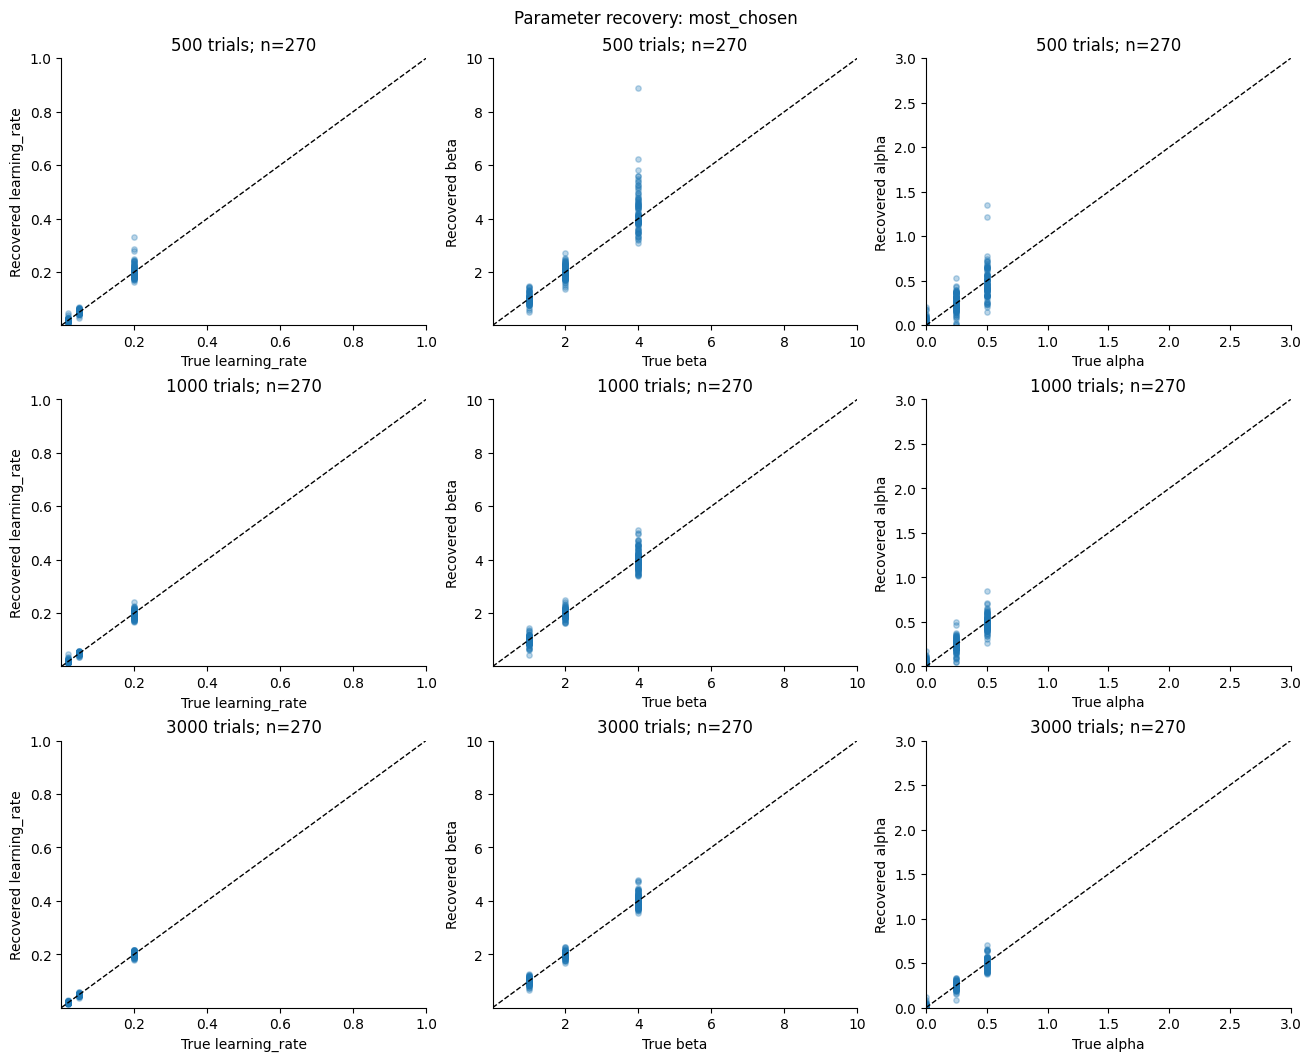

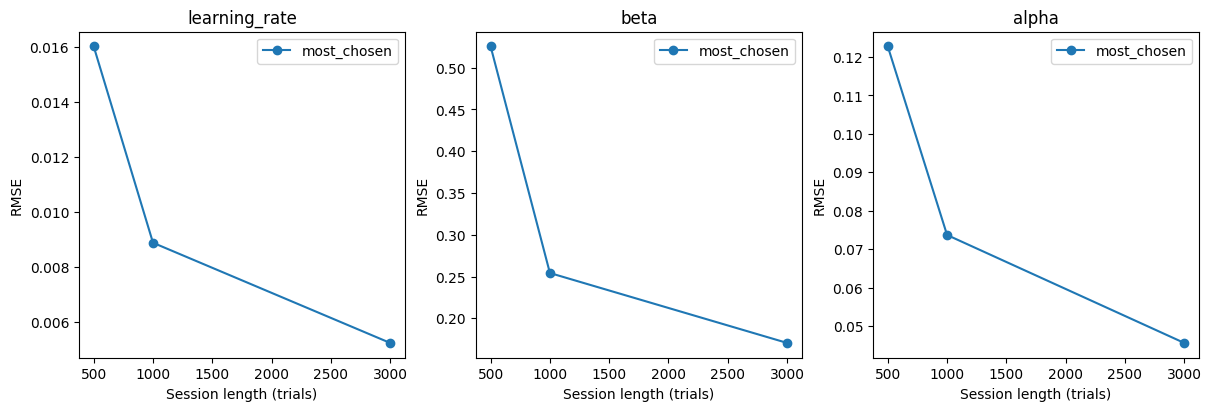

In [27]:
# True versus recovered values, separated by swap mode and session length.
successful = recovery_results.loc[recovery_results.success].copy()
for mode in recovery_config["swap_modes"]:
    lengths = recovery_config["trial_lengths"]
    fig, axes = plt.subplots(len(lengths), 3, figsize=(13, 3.5 * len(lengths)),
                             squeeze=False, layout="constrained")
    for row_index, length in enumerate(lengths):
        subset = successful.loc[(successful.swap_mode == mode)
                                & (successful.num_trials == length)]
        for col_index, (name, limits) in enumerate(zip(PARAMETER_NAMES, PARAMETER_BOUNDS)):
            ax = axes[row_index, col_index]
            ax.scatter(subset[f"true_{name}"], subset[f"recovered_{name}"],
                       s=15, alpha=0.3)
            ax.plot(limits, limits, "--", color="black", linewidth=1)
            ax.set(xlim=limits, ylim=limits, xlabel=f"True {name}",
                   ylabel=f"Recovered {name}", title=f"{length} trials; n={len(subset)}")
            ax.spines[["top", "right"]].set_visible(False)
    fig.suptitle(f"Parameter recovery: {mode}")
    fig.savefig(recovery_output_dir / f"recovery_{mode}.png", dpi=160)
    plt.show()

# How recovery error changes with available data.
fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout="constrained")
for ax, name in zip(axes, PARAMETER_NAMES):
    for mode in recovery_config["swap_modes"]:
        subset = recovery_summary.loc[(recovery_summary.parameter == name)
                                      & (recovery_summary.swap_mode == mode)].sort_values("num_trials")
        ax.plot(subset.num_trials, subset.rmse, "o-", label=mode)
    ax.set(xlabel="Session length (trials)", ylabel="RMSE", title=name)
    ax.legend()
fig.savefig(recovery_output_dir / "rmse_by_session_length.png", dpi=160)
plt.show()

### Parameter trade-offs
The heatmaps correlate **estimation errors**, not raw estimates, within each task/length condition. Off-diagonal relationships can reveal compensating parameter estimates, but also reflect the mixture of generating settings; inspect `recovery_by_setting` before interpreting them. The final table compares recovery of the effective stickiness coefficient `beta * alpha` with its true value. These diagnostics do not provide confidence intervals or establish unique parameter identification.

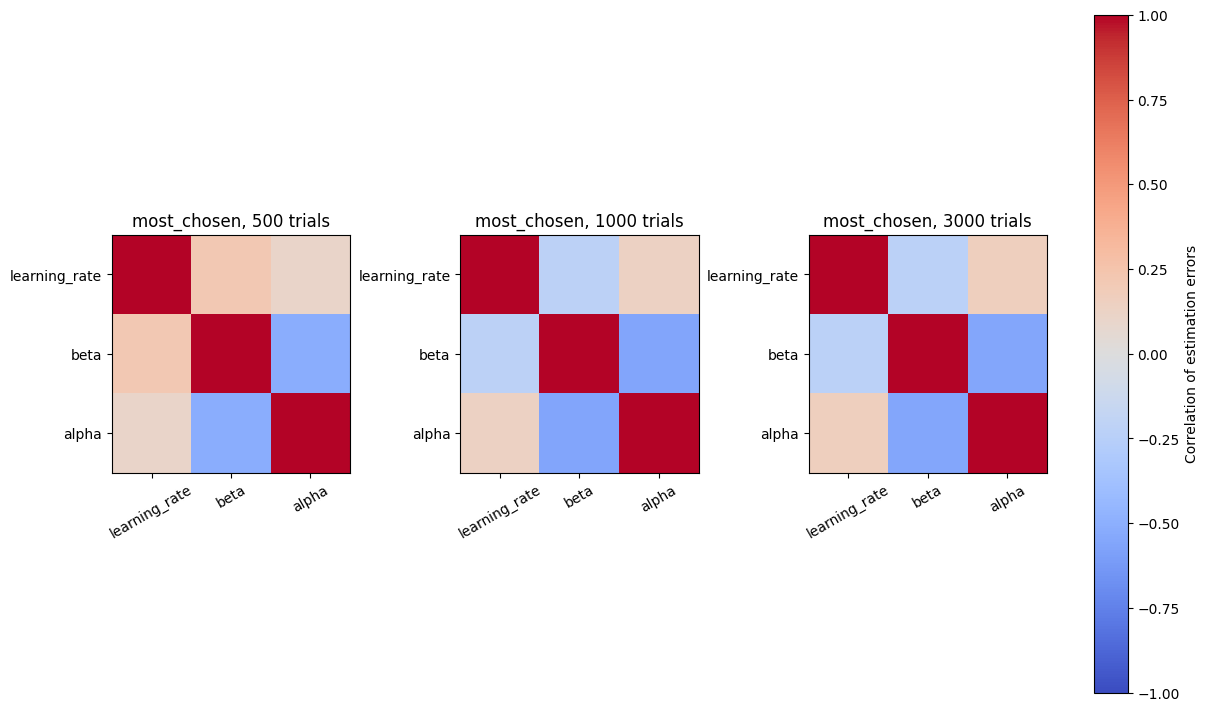

,swap_mode,num_trials,n_success,beta_alpha_bias,beta_alpha_rmse
0,most_chosen,500,270,0.005162,0.194088
1,most_chosen,1000,270,0.005129,0.123488
2,most_chosen,3000,270,0.006621,0.067850


In [28]:
tradeoff_rows = []
fig, axes = plt.subplots(len(recovery_config["swap_modes"]),
                         len(recovery_config["trial_lengths"]),
                         figsize=(12, 7), squeeze=False, layout="constrained")
for row_index, mode in enumerate(recovery_config["swap_modes"]):
    for col_index, length in enumerate(recovery_config["trial_lengths"]):
        subset = successful.loc[(successful.swap_mode == mode)
                                & (successful.num_trials == length)]
        errors = pd.DataFrame({name: subset[f"recovered_{name}"] - subset[f"true_{name}"]
                               for name in PARAMETER_NAMES})
        ax = axes[row_index, col_index]
        im = ax.imshow(errors.corr(), vmin=-1, vmax=1, cmap="coolwarm")
        ax.set_xticks(range(3), PARAMETER_NAMES, rotation=30)
        ax.set_yticks(range(3), PARAMETER_NAMES)
        ax.set_title(f"{mode}, {length} trials")
        product_error = (subset.recovered_beta * subset.recovered_alpha
                         - subset.true_beta * subset.true_alpha)
        tradeoff_rows.append({"swap_mode": mode, "num_trials": length,
                             "n_success": len(subset),
                             "beta_alpha_bias": product_error.mean(),
                             "beta_alpha_rmse": np.sqrt((product_error ** 2).mean())})
fig.colorbar(im, ax=axes.ravel().tolist(), label="Correlation of estimation errors")
fig.savefig(recovery_output_dir / "parameter_error_correlations.png", dpi=160)
plt.show()
tradeoff_summary = pd.DataFrame(tradeoff_rows)
tradeoff_summary.to_csv(recovery_output_dir / "effective_stickiness_summary.csv", index=False)
display(tradeoff_summary)

## Cohort 1: fit problems 5–11 with leave-one-problem-out validation
This section can run independently of the synthetic recovery sweep. MY_71_N has six fits over problems 5–10 (train on five, test on one). Each other mouse has seven fits over problems 5–11 (train on six, test on one). Problems use the **existing analysis pipeline's ordinal numbering**, assigned from the full eligible session history before selecting 5–11. Raw `num_problem` values are not used.

The model uses learning rate, beta, and nonnegative stickiness alpha, with the same softmax parameterisation as the simulation. Rewards are **delivered reward pulses** (`reward_pulses`), including zeros. Arm identities are physical tower labels, never reward ranks. Q-values and previous-choice memory reset at each extracted session (including configuration-split sessions); this is an explicit modelling assumption. Training loss is trial-weighted across training sessions for that mouse.

Held-out choices are predicted before each reward update. Past held-out observations update Q-values during sequential scoring, but fitted parameters remain fixed. No held-out outcomes are used to optimise parameters or select optimisation starts. The folds overlap in training data, so they are not independent subjects. This evaluates generalisation across problems, not strictly forward-in-time forecasting.

Sessions with missing/invalid choice or reward histories are excluded as a whole and audited. Mice need usable data in every problem requested for that mouse; MY_71_N has an explicit exception because problem 11 is unavailable. Fits at parameter bounds are flagged. Do not tune model settings against these held-out scores and then treat the same scores as untouched test performance.

In [1]:
# Independent setup: no need to run the synthetic recovery experiment first.
import importlib
import json
import sys
from pathlib import Path
from unittest.mock import patch

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

cohort_repo_root = next(
    (p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
     if (p / "src/behavior_import").is_dir()), None
)
if cohort_repo_root is None:
    raise RuntimeError("Run this notebook from within the repository.")
if str(cohort_repo_root) not in sys.path:
    sys.path.insert(0, str(cohort_repo_root))

from src.agents.cohort_fitting import (
    prepare_cohort_sequences, run_problem_cross_validation,
)
from src.behavior_import.extract_trials import extract_trials_grouped_by_problem
cohort_import = importlib.import_module("src.behavior_import.import_data")

# Match the existing cohort-1 analysis notebook. Mount the drive or edit this path.
cohort_data_root = Path("/Volumes/behrens/meg/3x3_field_magnitude_bandit/rawdata/cohort-01")
cohort_problem_numbers = list(range(5, 12))
cohort_excluded_task_parts = ("mag", "pretraining")
cohort_fit_bounds = [(0.001, 1.0), (0.01, 10.0), (0.0, 3.0)]
cohort_fit_starts = 10
cohort_fit_seed = 42
cohort_output_root = cohort_repo_root / "results/cohort_01_parameter_fitting"
# Explicit exception: six folds for this mouse; seven for all others.
cohort_problem_overrides = {"MY_71_N": list(range(5, 11))}


In [2]:
# Load all eligible sessions first: filtering to later sessions beforehand
# would change the pipeline's ordinal problem numbering.
if not cohort_data_root.is_dir():
    raise FileNotFoundError(
        f"Cohort 1 data not found: {cohort_data_root}. "
        "Mount the data drive or set cohort_data_root to the full cohort directory."
    )
cohort_files = cohort_import.collect_tsv_files(cohort_data_root.resolve())
cohort_eligible_files = []
cohort_file_rows = []
for path, frame in cohort_files:
    task_rows = frame.loc[
        frame["type"].eq("info") & frame["subtype"].eq("task_name"), "content"
    ]
    task_name = str(task_rows.iloc[0]) if len(task_rows) else None
    keep = task_name is not None and not any(
        part in task_name.casefold() for part in cohort_excluded_task_parts
    )
    cohort_file_rows.append({"path": str(path), "task_name": task_name, "included": keep})
    if keep:
        cohort_eligible_files.append((path, frame))
cohort_file_audit = pd.DataFrame(cohort_file_rows, columns=["path", "task_name", "included"])
display(cohort_file_audit.groupby(["task_name", "included"], dropna=False).size().rename("files"))
if not cohort_eligible_files:
    raise ValueError("No eligible task files remain; check the root and the task-name audit.")
with patch.object(cohort_import, "collect_tsv_files", return_value=cohort_eligible_files):
    cohort_raw = cohort_import.import_data(cohort_data_root)
cohort_all_problems = extract_trials_grouped_by_problem(cohort_raw, merge_recurring_problems=False)
print("Available pipeline problem numbers:", sorted(cohort_all_problems))
missing_problems = sorted(set(cohort_problem_numbers) - set(cohort_all_problems))
if missing_problems:
    raise ValueError(
        f"Missing requested pipeline problems: {missing_problems}. "
        "Check the complete cohort data and task filtering; problem numbers will not be relabelled."
    )
cohort_sequences, cohort_session_audit = prepare_cohort_sequences(
    cohort_all_problems, cohort_problem_numbers
)
display(cohort_session_audit.groupby(["mouse", "problem", "included"]).agg(
    sessions=("session", "size"), trials=("n_trials", "sum")
))
display(cohort_session_audit.loc[~cohort_session_audit.included])

[WARN] Failed to read /Volumes/behrens/meg/3x3_field_magnitude_bandit/rawdata/cohort-01/sub-03_id-MY_71_R/ses-185_date-20260702/behav/._MY_71_R-2026-07-02-155715.tsv: 'utf-8' codec can't decode byte 0xb0 in position 37: invalid start byte.
[WARN] Failed to read /Volumes/behrens/meg/3x3_field_magnitude_bandit/rawdata/cohort-01/sub-03_id-MY_71_R/ses-177_date-20260624/behav/._MY_71_R-2026-06-24-191859.tsv: 'utf-8' codec can't decode byte 0xb0 in position 37: invalid start byte.
[WARN] Failed to read /Volumes/behrens/meg/3x3_field_magnitude_bandit/rawdata/cohort-01/sub-04_id-MY_72_N/ses-38_date-20260224/behav/._MY_72_N-2026-02-24-171733.tsv: 'utf-8' codec can't decode byte 0xb0 in position 37: invalid start byte.
[WARN] Failed to read /Volumes/behrens/meg/3x3_field_magnitude_bandit/rawdata/cohort-01/sub-04_id-MY_72_N/ses-39_date-20260225/behav/._MY_72_N-2026-02-25-103701.tsv: 'utf-8' codec can't decode byte 0xb0 in position 37: invalid start byte.
[WARN] Failed to read /Volumes/behrens/meg

task_name                                              included
Meg\3x3_field_blocked_reward_bandit_with_cue           True        316
Meg\3x3_field_drifting_value_bandit                    True        467
Meg\3x3_field_drifting_value_bandit_for_recording_71R  True        126
Meg\3x3_field_drifting_value_bandit_for_recording_72L  True         83
Name: files, dtype: int64

sessions  trials
mouse   problem included                  
MY_71_L 5       True             8     462
        6       True             7     436
        7       True             9     503
        8       True             8     442
        9       True             7     326
        10      True             8     519
        11      True             6     413
MY_71_N 5       True             8     518
        6       True             8     500
        7       True             7     382
        8       True             7     357
        9       True             6     387
        10      True             5     315
MY_71_R 5       True             7     475
        6       True             7     456
        7       True             8     480
        8       True             7     427
        9       True             6     318
        10      True             8     537
        11      True             6     421
MY_72_L 5       True             8     429
        6       True             6     458
        7       True            10     551
        8       True             8     414
        9       True             9     367
        10      True             6     419
        11      True             8     512
MY_72_N 5       True             9     381
        6       True             6     416
        7       True             7     476
        8       True             8     441
        9       True             8     361
        10      True             7     445
        11      True             8     463
MY_72_R 5       True            10     562
        6       True             8     523
        7       True             8     537
        8       True             8     484
        9       True             7     393
        10      True             8     658
        11      True             8     615

,mouse,problem,session,n_trials,included,reason,reward_min,reward_max,towers


In [3]:
# Run/resume all seven folds for each eligible mouse. Each fold is saved.
cohort_cv_results, cohort_test_sessions, cohort_eligibility, cohort_fit_dir = (
    run_problem_cross_validation(
        cohort_sequences, cohort_output_root,
        problem_numbers=cohort_problem_numbers, bounds=cohort_fit_bounds,
        n_starts=cohort_fit_starts, seed=cohort_fit_seed,
        source_metadata={
            "root": str(cohort_data_root.resolve()),
            "excluded_task_name_parts": list(cohort_excluded_task_parts),
            "problem_numbering": "existing_pipeline_contiguous_ordinal",
            "merge_recurring_problems": False,
        },
    )
)
cohort_file_audit.to_csv(cohort_fit_dir / "input_files.csv", index=False)
cohort_session_audit.to_csv(cohort_fit_dir / "session_audit.csv", index=False)
# Include mice whose every requested session was rejected by data validation.
audit_mice = set(cohort_session_audit.mouse)
missing_mice = audit_mice - set(cohort_eligibility.mouse)
if missing_mice:
    cohort_eligibility = pd.concat([
        cohort_eligibility,
        pd.DataFrame([{"mouse": mouse, "eligible": False,
                       "missing_problems": ",".join(map(str, cohort_problem_numbers))}
                      for mouse in sorted(missing_mice)]),
    ], ignore_index=True)
cohort_eligibility.to_csv(cohort_fit_dir / "mouse_eligibility.csv", index=False)
display(cohort_eligibility)
if cohort_cv_results.empty:
    raise ValueError(f"No mice have usable trials in all seven problems. See audits in {cohort_fit_dir}.")
display(cohort_cv_results)
print(f"Saved fits, optimisation starts, and held-out trial predictions to {cohort_fit_dir}")

# Preserve the original seven-fold run and fit the explicit six-fold exception.
cohort_seven_fold_dir = cohort_fit_dir
cohort_run_dirs = {"seven_fold": str(cohort_seven_fold_dir)}
for exception_mouse, exception_problems in cohort_problem_overrides.items():
    exception_sequences = [s for s in cohort_sequences if s["mouse"] == exception_mouse]
    extra_results, extra_sessions, extra_eligibility, extra_dir = run_problem_cross_validation(
        exception_sequences, cohort_output_root,
        problem_numbers=exception_problems, bounds=cohort_fit_bounds,
        n_starts=cohort_fit_starts, seed=cohort_fit_seed,
        source_metadata={
            "root": str(cohort_data_root.resolve()),
            "excluded_task_name_parts": list(cohort_excluded_task_parts),
            "problem_numbering": "existing_pipeline_contiguous_ordinal",
            "merge_recurring_problems": False,
            "mouse": exception_mouse,
        },
    )
    cohort_run_dirs[exception_mouse] = str(extra_dir)
    cohort_cv_results = pd.concat([
        cohort_cv_results.loc[cohort_cv_results.mouse.ne(exception_mouse)], extra_results
    ], ignore_index=True)
    cohort_test_sessions = pd.concat([
        cohort_test_sessions.loc[cohort_test_sessions.mouse.ne(exception_mouse)], extra_sessions
    ], ignore_index=True)
    cohort_eligibility = pd.concat([
        cohort_eligibility.loc[cohort_eligibility.mouse.ne(exception_mouse)], extra_eligibility
    ], ignore_index=True)
cohort_fit_dir = cohort_output_root / "combined_with_MY_71_N_six_folds"
cohort_fit_dir.mkdir(parents=True, exist_ok=True)
cohort_eligibility["requested_problems"] = cohort_eligibility.mouse.map(
    lambda m: ",".join(map(str, cohort_problem_overrides.get(m, cohort_problem_numbers))))
cohort_eligibility["expected_folds"] = cohort_eligibility.mouse.map(
    lambda m: len(cohort_problem_overrides.get(m, cohort_problem_numbers)))
cohort_cv_results = cohort_cv_results.sort_values(["mouse", "held_out_problem"])
cohort_cv_results.to_csv(cohort_fit_dir / "fold_results.csv", index=False)
cohort_test_sessions.to_csv(cohort_fit_dir / "held_out_sessions.csv", index=False)
cohort_eligibility.to_csv(cohort_fit_dir / "mouse_eligibility.csv", index=False)
cohort_file_audit.to_csv(cohort_fit_dir / "input_files.csv", index=False)
cohort_session_audit.to_csv(cohort_fit_dir / "session_audit.csv", index=False)
(cohort_fit_dir / "source_runs.json").write_text(json.dumps(cohort_run_dirs, indent=2))
display(cohort_eligibility)
print(f"Combined results saved to {cohort_fit_dir}; detailed fits/predictions remain in source runs.")


Saved fits, optimisation starts, and held-out trial predictions to /Users/megyoung/magnitude-bandit-analysis/results/cohort_01_parameter_fitting/11dfc0c26682
MY_71_N: held out problem 5; fit saved
MY_71_N: held out problem 6; fit saved
MY_71_N: held out problem 7; fit saved
MY_71_N: held out problem 8; fit saved
MY_71_N: held out problem 9; fit saved
MY_71_N: held out problem 10; fit saved
Combined results saved to /Users/megyoung/magnitude-bandit-analysis/results/cohort_01_parameter_fitting/combined_with_MY_71_N_six_folds; detailed fits/predictions remain in source runs.


,mouse,eligible,missing_problems
0,MY_71_L,True,
1,MY_71_N,False,11
2,MY_71_R,True,
3,MY_72_L,True,
4,MY_72_N,True,
5,MY_72_R,True,


,mouse,held_out_problem,training_problems,n_train_trials,n_test_trials,n_train_sessions,n_test_sessions,success,converged_starts,train_cross_entropy,test_cross_entropy,uniform_cross_entropy,improvement_over_uniform,learning_rate,at_bound_learning_rate,beta,at_bound_beta,alpha,at_bound_alpha
0,MY_71_L,5,"6,7,8,9,10,11",2639,462,45,8,True,10,0.577626,0.891819,1.098612,0.206794,0.319790,False,0.699555,False,1.938345,False
1,MY_71_L,6,"5,7,8,9,10,11",2665,436,46,7,True,10,0.630765,0.576193,1.098612,0.522419,0.316242,False,0.648878,False,1.940604,False
2,MY_71_L,7,"5,6,8,9,10,11",2598,503,44,9,True,10,0.646289,0.504980,1.098612,0.593632,0.312669,False,0.622420,False,2.052280,False
3,MY_71_L,8,"5,6,7,9,10,11",2659,442,45,8,True,10,0.645787,0.489836,1.098612,0.608776,0.303027,False,0.662273,False,1.776178,False
4,MY_71_L,9,"5,6,7,8,10,11",2775,326,46,7,True,10,0.613872,0.702435,1.098612,0.396177,0.298309,False,0.700117,False,1.745152,False
5,MY_71_L,10,"5,6,7,8,9,11",2582,519,45,8,True,10,0.604135,0.718166,1.098612,0.380446,0.320834,False,0.676251,False,1.893414,False
6,MY_71_L,11,"5,6,7,8,9,10",2688,413,47,6,True,10,0.639400,0.519987,1.098612,0.578626,0.280115,False,0.682438,False,1.765150,False
7,MY_71_R,5,"6,7,8,9,10,11",2639,475,42,7,True,10,0.773217,0.845982,1.098612,0.252630,0.262293,False,0.581665,False,1.613500,False
8,MY_71_R,6,"5,7,8,9,10,11",2658,456,42,7,True,10,0.778542,0.814809,1.098612,0.283803,0.229239,False,0.605225,False,1.513477,False
9,MY_71_R,7,"5,6,8,9,10,11",2634,480,41,8,True,10,0.799440,0.698502,1.098612,0.400110,0.227602,False,0.621536,False,1.346912,False


,mouse,eligible,missing_problems,requested_problems,expected_folds
0,MY_71_L,True,,"5,6,7,8,9,10,11",7
1,MY_71_R,True,,"5,6,7,8,9,10,11",7
2,MY_72_L,True,,"5,6,7,8,9,10,11",7
3,MY_72_N,True,,"5,6,7,8,9,10,11",7
4,MY_72_R,True,,"5,6,7,8,9,10,11",7
5,MY_71_N,True,,"5,6,7,8,9,10",6


### Held-out performance and parameter stability
Cross entropy is measured in nats per choice; lower is better. Positive improvement over `log(3)` means better prediction than uniform choice. This is a minimal baseline, not evidence that Q-learning outperforms other behavioural models.

Per-mouse aggregate scores are reported only when all requested folds succeed (six for MY_71_N, seven for other mice). Each held-out trial then appears exactly once in the aggregate; trial-weighting differs from giving each problem equal weight. Across-mouse summaries give each mouse equal weight. Parameter plots show the six or seven training-fold estimates per mouse, not seven independent estimates or confidence intervals. These are cross-validation fits, not an additional all-problems refit.

Mice with all requested folds complete: 6
Mean across mice (equal mouse weight): 0.747329010867022
Failed folds: 0


,n_folds,total_held_out_nll,total_held_out_trials,mean_problem_cross_entropy,trial_weighted_cross_entropy,improvement_over_uniform
mouse,,,,,,
MY_71_L,7,1950.229616,3101,0.629059,0.628903,0.469709
MY_71_N,6,1924.221750,2459,0.780518,0.782522,0.316090
MY_71_R,7,2458.169001,3114,0.788641,0.789393,0.309220
MY_72_L,7,2228.930668,3150,0.709864,0.707597,0.391015
MY_72_N,7,2350.827274,2983,0.794043,0.788075,0.310537
MY_72_R,7,2970.389341,3772,0.786940,0.787484,0.311128


,mouse,held_out_problem,learning_rate,beta,alpha,at_bound_learning_rate,at_bound_beta,at_bound_alpha
0,MY_71_L,5,0.319790,0.699555,1.938345,False,False,False
1,MY_71_L,6,0.316242,0.648878,1.940604,False,False,False
2,MY_71_L,7,0.312669,0.622420,2.052280,False,False,False
3,MY_71_L,8,0.303027,0.662273,1.776178,False,False,False
4,MY_71_L,9,0.298309,0.700117,1.745152,False,False,False
5,MY_71_L,10,0.320834,0.676251,1.893414,False,False,False
6,MY_71_L,11,0.280115,0.682438,1.765150,False,False,False
35,MY_71_N,5,0.193333,0.452428,3.000000,False,False,True
36,MY_71_N,6,0.204062,0.515781,2.172420,False,False,False
37,MY_71_N,7,0.154136,0.522205,2.340277,False,False,False


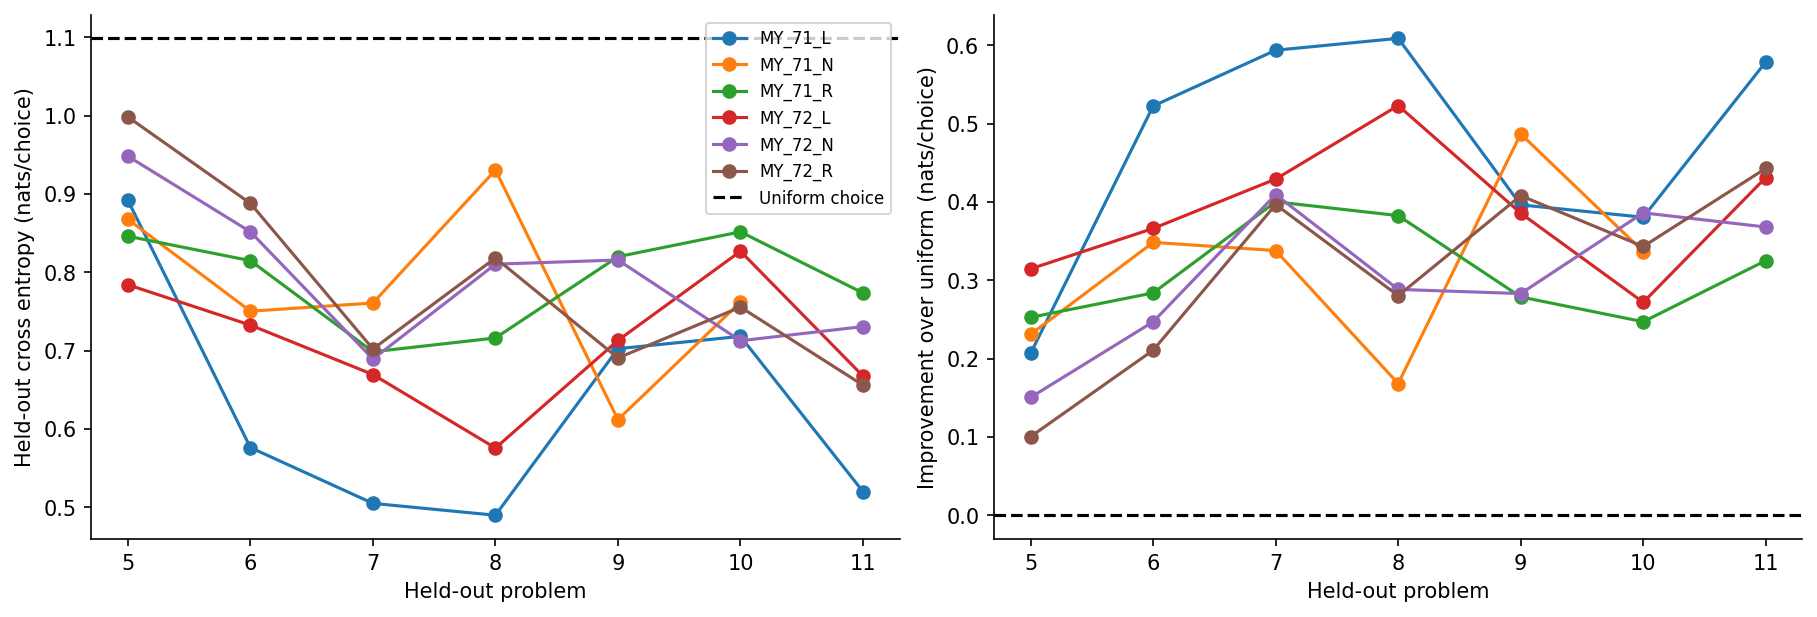

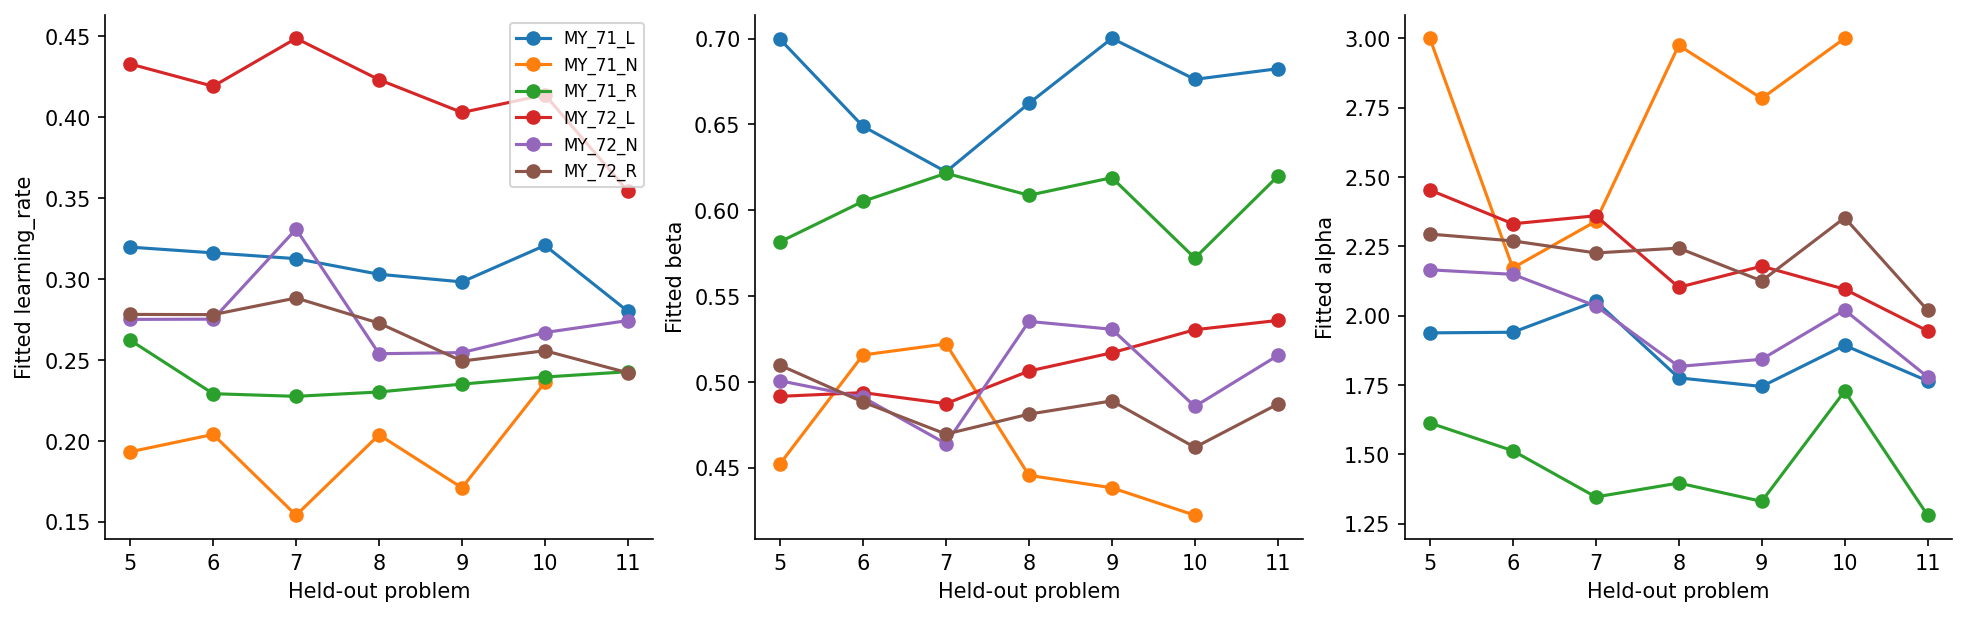

In [5]:
cohort_cv_success = cohort_cv_results.loc[cohort_cv_results.success].copy()
cohort_cv_success["held_out_nll"] = (
    cohort_cv_success.test_cross_entropy * cohort_cv_success.n_test_trials
)
complete_mice = cohort_cv_success.groupby("mouse").held_out_problem.nunique()
expected_folds = pd.Series({m: len(cohort_problem_overrides.get(m, cohort_problem_numbers))
                            for m in complete_mice.index})
complete_mice = complete_mice.index[complete_mice.eq(expected_folds)]
cohort_complete_folds = cohort_cv_success.loc[cohort_cv_success.mouse.isin(complete_mice)]
cohort_mouse_scores = cohort_complete_folds.groupby("mouse").agg(
    n_folds=("held_out_problem", "nunique"),
    total_held_out_nll=("held_out_nll", "sum"),
    total_held_out_trials=("n_test_trials", "sum"),
    mean_problem_cross_entropy=("test_cross_entropy", "mean"),
)
cohort_mouse_scores["trial_weighted_cross_entropy"] = (
    cohort_mouse_scores.total_held_out_nll / cohort_mouse_scores.total_held_out_trials
)
cohort_mouse_scores["improvement_over_uniform"] = (
    np.log(3) - cohort_mouse_scores.trial_weighted_cross_entropy
)
cohort_mouse_scores.to_csv(cohort_fit_dir / "mouse_cv_scores.csv")
display(cohort_mouse_scores)
print(f"Mice with all requested folds complete: {len(complete_mice)}")
print("Mean across mice (equal mouse weight):",
      cohort_mouse_scores.trial_weighted_cross_entropy.mean())
print("Failed folds:", int((~cohort_cv_results.success).sum()))
display(cohort_cv_success[["mouse", "held_out_problem", "learning_rate", "beta", "alpha",
                          "at_bound_learning_rate", "at_bound_beta", "at_bound_alpha"]])

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for mouse, group in cohort_cv_success.groupby("mouse"):
    group = group.sort_values("held_out_problem")
    axes[0].plot(group.held_out_problem, group.test_cross_entropy, "o-", label=mouse)
    axes[1].plot(group.held_out_problem, group.improvement_over_uniform, "o-", label=mouse)
axes[0].axhline(np.log(3), color="black", linestyle="--", label="Uniform choice")
axes[1].axhline(0, color="black", linestyle="--")
axes[0].set_ylabel("Held-out cross entropy (nats/choice)")
axes[1].set_ylabel("Improvement over uniform (nats/choice)")
for ax in axes:
    ax.set_xlabel("Held-out problem")
    ax.set_xticks(cohort_problem_numbers)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(fontsize=8)
fig.savefig(cohort_fit_dir / "held_out_performance.png", dpi=160)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout="constrained")
for ax, parameter in zip(axes, ["learning_rate", "beta", "alpha"]):
    for mouse, group in cohort_cv_success.groupby("mouse"):
        group = group.sort_values("held_out_problem")
        ax.plot(group.held_out_problem, group[parameter], "o-", label=mouse)
    ax.set(xlabel="Held-out problem", ylabel=f"Fitted {parameter}")
    ax.set_xticks(cohort_problem_numbers)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(fontsize=8)
fig.savefig(cohort_fit_dir / "parameter_stability_across_folds.png", dpi=160)
plt.show()

### Parameter values across mice
Each coloured dot is one training-fold estimate; black bars show their mean. MY_71_N uses six folds over problems 5–10; the other mice use seven folds over problems 5–11. Folds overlap in training data, so their spread is not a confidence interval. These are not all-problems refits.

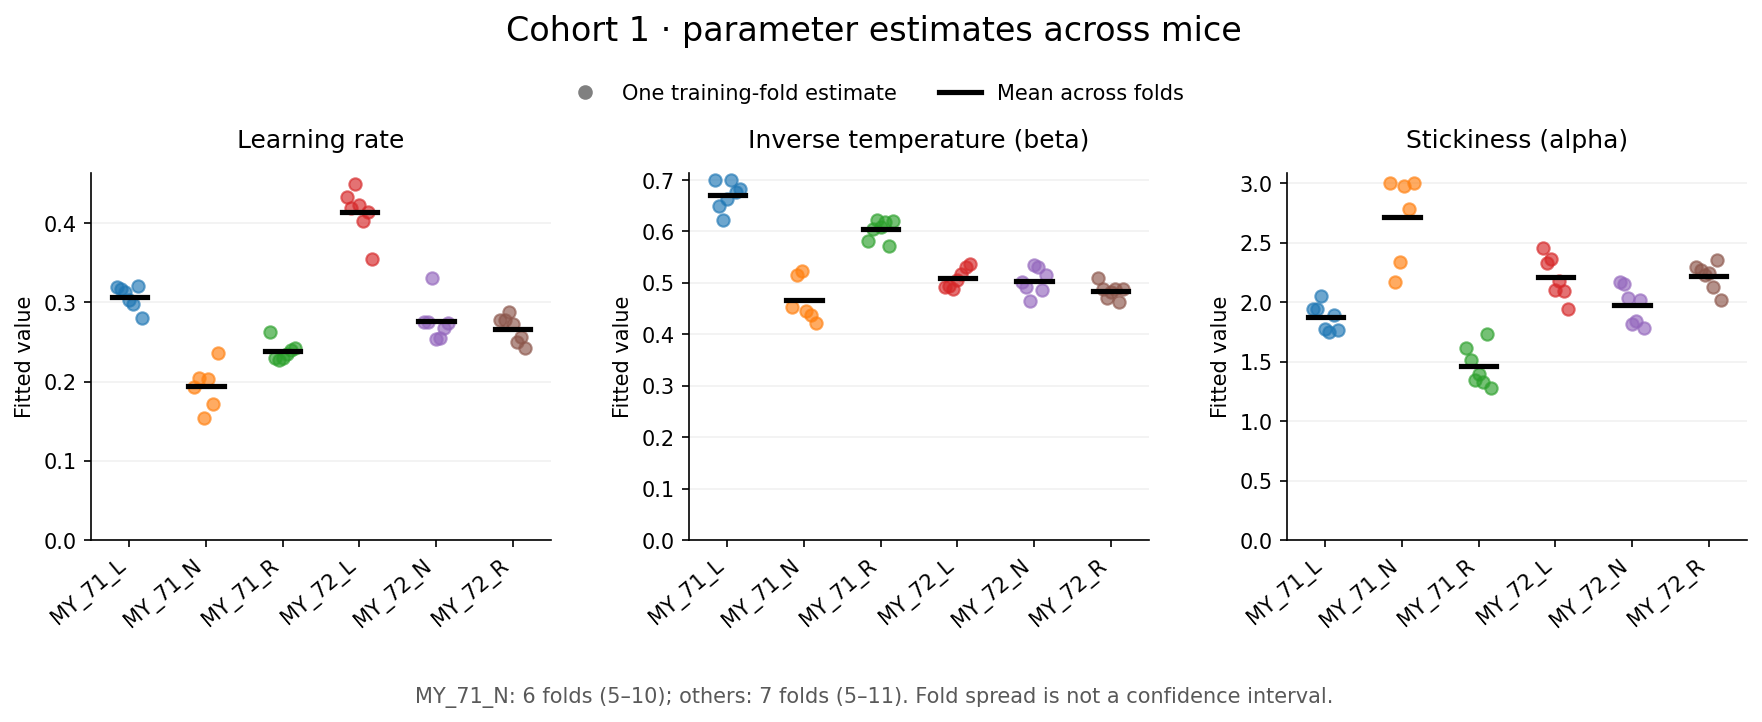

In [7]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

plot_repo_root = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                      if (p / "src/agents/cohort_fitting.py").exists())
parameter_plot_dir = Path(globals().get(
    "cohort_fit_dir",
    plot_repo_root / "results/cohort_01_parameter_fitting/combined_with_MY_71_N_six_folds",
))
parameter_folds = pd.read_csv(parameter_plot_dir / "fold_results.csv")
parameter_folds = parameter_folds.loc[parameter_folds.success].copy()
parameter_mice = sorted(parameter_folds.mouse.unique())
parameter_names = ["learning_rate", "beta", "alpha"]
parameter_titles = ["Learning rate", "Inverse temperature (beta)", "Stickiness (alpha)"]
parameter_means = parameter_folds.groupby("mouse")[parameter_names].mean().reindex(parameter_mice)
parameter_means.to_csv(parameter_plot_dir / "parameter_means_across_folds.csv")

fig, axes = plt.subplots(1, 3, figsize=(12, 4.8))
colors = plt.get_cmap("tab10").colors
for ax, name, title in zip(axes, parameter_names, parameter_titles):
    for i, mouse_name in enumerate(parameter_mice):
        values = parameter_folds.loc[parameter_folds.mouse.eq(mouse_name)].sort_values("held_out_problem")[name]
        offsets = np.linspace(-0.16, 0.16, len(values))
        ax.scatter(i + offsets, values, s=35, color=colors[i], alpha=0.65, zorder=3)
        ax.plot([i - 0.23, i + 0.23], [values.mean()] * 2,
                color="black", linewidth=2.5, zorder=4)
    ax.set_title(title, fontsize=12, pad=12)
    ax.set_xticks(range(len(parameter_mice)), parameter_mice, rotation=40, ha="right")
    ax.set_ylabel("Fitted value")
    ax.set_xlim(-0.5, len(parameter_mice) - 0.5)
    ax.set_ylim(bottom=0)
    ax.grid(axis="y", alpha=0.18)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Cohort 1 · parameter estimates across mice", fontsize=16, y=0.98)
fig.legend(handles=[
    Line2D([], [], color="0.5", marker="o", linestyle="none", label="One training-fold estimate"),
    Line2D([], [], color="black", linewidth=2.5, label="Mean across folds"),
], loc="upper center", bbox_to_anchor=(0.5, 0.91), ncol=2, frameon=False)
fig.text(0.5, 0.025, "MY_71_N: 6 folds (5–10); others: 7 folds (5–11). Fold spread is not a confidence interval.",
         ha="center", fontsize=10, color="0.35")
fig.subplots_adjust(top=0.76, bottom=0.25, left=0.065, right=0.985, wspace=0.30)
for extension in ("png", "pdf"):
    fig.savefig(parameter_plot_dir / f"parameters_across_mice.{extension}", dpi=180, bbox_inches="tight")
plt.show()


## Best RL: six-parameter extension

Source: `combined.pdf`, Supplementary Methods, printed pp. 9–10 and 15–16 (PDF pp. 29–30 and 35–36). This section adds Best RL without replacing the three-parameter model above. Here `learning_rate` corresponds to paper α, and `kappa` to paper perseverance κ (the existing model calls stickiness `alpha`).

Before each choice: `p = softmax(beta * (Q + kappa * previous_choice_one_hot))`. After receiving reward, the chosen value receives `learning_rate * (reward - Q_chosen) + bias`; then **all** values decay as `Q = (1-forgetting) * Q + forgetting * q_init`. Each session begins at `q_init`, with no previous choice. The paper specifies all-action decay but does not explicitly resolve update/decay ordering; we adopt update then decay consistently in simulation and fitting. The main-text figure caption describes unchosen-action decay, whereas Supplementary Eq. 5 says all actions; this implementation follows Eq. 5.

Ranges follow the paper using direct optimizer bounds, with numerical epsilon 1e-6 at open endpoints: learning rate and forgetting in (0,1), kappa and bias in (-1,1), beta positive without an upper bound, and q_init unrestricted. Rewards remain delivered pulses (simulation: supplied magnitudes). Reward units affect beta, bias, kappa and q_init; this does not reproduce the paper's four-arm human task or establish a reward preprocessing match.

### Differences in fitting

Both implementations minimize choice cross entropy, scoring choices before observing their rewards and conditioning later predictions on the observed history. Our loss is mean NLL per trial; the paper sums NLL within fixed-length minibatches (same unregularized optimum, different scaling).

The paper uses shared parameters across participants, participant-disjoint 80% training / 10% validation / 10% test splits, minibatch Adam in JAX/Optax, five instantiations per hyperparameter setting, and validation-based selection of training duration and hyperparameters. Its chosen Best RL settings are 300,000 steps, optimizer learning rate 1e-4, L2 weight 1e-5, batch size 32. The optimizer learning rate is distinct from behavioral learning rate α.

Here both models use full-data, multi-start L-BFGS-B without regularization; each mouse has its own parameters, with leave-one-problem-out testing and resets per extracted session. Keeping the same fitting protocol isolates the architectural comparison. This is an architecture implementation, not a replication of the paper's training procedure. `exp(-cross_entropy)` is the geometric mean assigned probability, not argmax percent-correct accuracy. Six parameters may require more starts and stronger recovery checks; lower training loss alone does not establish better prediction or identification.

**Structural identifiability limitation:** under the equations above, define `x = Q - q_init`. The chosen update depends on `learning_rate * reward + bias - learning_rate * q_init`, and a common value offset cancels in softmax. Thus bias and q_init cannot be uniquely recovered from choice likelihood: adding δ to q_init and `learning_rate * δ` to bias leaves every prediction unchanged (within allowed bounds). Six nominal parameters provide at most five identifiable combinations. We retain all six to match the architecture, but interpret `bias - learning_rate * q_init`, not their separate estimates. To estimate them separately requires an additional constraint or information; more trials alone cannot resolve this.


In [ ]:
# Independent imports; this section can run without the earlier recovery sweep.
import sys
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display
best_repo_root = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                      if (p / "src/agents/best_rl.py").exists())
if str(best_repo_root) not in sys.path:
    sys.path.insert(0, str(best_repo_root))
from src.agents.best_rl import (
    BestRLMouse, PARAMETER_NAMES as BEST_RL_PARAMETER_NAMES,
    DEFAULT_BOUNDS as BEST_RL_BOUNDS, fit_mouse_sessions as fit_best_rl,
    multi_session_loss as best_rl_loss,
)
from src.tasks.drifting_bandit import DriftingBanditTask
from src.agents.cohort_fitting import run_problem_cross_validation


### Synthetic Best RL recovery example
A single fresh synthetic session illustrates simulation and fitting. This is a smoke/recovery example, not a factorial identification study. It leaves the original session and recovery results intact. Run this cell explicitly; it may take time.


In [ ]:
best_generating_params = dict(learning_rate=0.25, beta=2.0, kappa=0.2,
                              bias=0.05, forgetting=0.05, q_init=0.5)
# Preserve global RNG state used by other notebook simulations.
import random
best_numpy_state, best_python_state = np.random.get_state(), random.getstate()
try:
    np.random.seed(42)
    random.seed(42)
    best_task = DriftingBanditTask([0, 1, 4], drift_rate=0.1, swap_mode="most_chosen")
    best_mouse = BestRLMouse(3, **best_generating_params)
    best_actions, best_rewards, best_q_values = best_task.simulate(best_mouse, 1000)
finally:
    np.random.set_state(best_numpy_state)
    random.setstate(best_python_state)
best_synthetic_sequence = dict(towers=[0, 1, 2], actions=np.asarray(best_actions),
                               rewards=np.asarray(best_rewards, dtype=float))
best_synthetic_fit, best_synthetic_starts = fit_best_rl(
    [best_synthetic_sequence], n_starts=10, seed=42)
if best_synthetic_fit is None:
    raise RuntimeError("All Best RL starts failed; inspect best_synthetic_starts.")
best_recovery_table = pd.DataFrame({
    "true": best_generating_params,
    "recovered": dict(zip(BEST_RL_PARAMETER_NAMES, best_synthetic_fit["parameters"])),
})
best_recovery_table["error"] = best_recovery_table.recovered-best_recovery_table.true
display(best_recovery_table)
print("True loss:", best_rl_loss(list(best_generating_params.values()), [best_synthetic_sequence])[0])
print("Fitted loss:", best_synthetic_fit["loss"])
display(pd.DataFrame(best_synthetic_starts))

print("Identifiable bias combination (true / fitted):",
      best_generating_params["bias"]-best_generating_params["learning_rate"]*best_generating_params["q_init"],
      best_synthetic_fit["parameters"][3]-best_synthetic_fit["parameters"][0]*best_synthetic_fit["parameters"][5])


### Best RL cohort fits and matched held-out comparison
First run the existing cohort setup and data-loading cells (beginning `# Independent setup` and `# Load all eligible sessions first`). This uses the same sessions, pulses, tower identities, fold definitions and MY_71_N exception as the existing model. Outputs are stored separately and resume by manifest, including Best RL source and update order. No old three-parameter fits are overwritten. Fit starts are selected on training loss only.


In [ ]:
if "cohort_sequences" not in globals():
    raise RuntimeError("Run the cohort setup and data-loading cells first.")
best_fold_frames, best_session_frames, best_eligibility_frames = [], [], []
best_run_dirs = {}
for best_mouse_name in sorted({s["mouse"] for s in cohort_sequences}):
    best_mouse_sequences = [s for s in cohort_sequences if s["mouse"] == best_mouse_name]
    best_requested = cohort_problem_overrides.get(best_mouse_name, cohort_problem_numbers)
    best_folds, best_sessions, best_eligibility, best_dir = run_problem_cross_validation(
        best_mouse_sequences, cohort_output_root / "best_rl",
        problem_numbers=best_requested, bounds=BEST_RL_BOUNDS,
        n_starts=cohort_fit_starts, seed=cohort_fit_seed, model="best_rl",
        source_metadata={"root": str(cohort_data_root.resolve()),
                         "problem_numbering": "existing_pipeline_contiguous_ordinal",
                         "excluded_task_name_parts": list(cohort_excluded_task_parts)},
    )
    best_fold_frames.append(best_folds)
    best_session_frames.append(best_sessions)
    best_eligibility_frames.append(best_eligibility)
    best_run_dirs[best_mouse_name] = str(best_dir)
best_cohort_folds = pd.concat(best_fold_frames, ignore_index=True)
best_cohort_sessions = pd.concat(best_session_frames, ignore_index=True)
best_cohort_eligibility = pd.concat(best_eligibility_frames, ignore_index=True)
display(best_cohort_eligibility)
display(best_cohort_folds)
print("Detailed saved fits and predictions:", best_run_dirs)


In [ ]:
# Pair only identical held-out folds; failed/missing folds stay visible.
sticky_fold_path = cohort_output_root / "combined_with_MY_71_N_six_folds/fold_results.csv"
if not sticky_fold_path.exists():
    print("Run the existing three-parameter cohort fitting cell to produce comparison scores.")
else:
    sticky_folds = pd.read_csv(sticky_fold_path)
    compare_columns = ["mouse", "held_out_problem", "success", "n_test_trials", "test_cross_entropy"]
    best_comparison = sticky_folds[compare_columns].merge(
        best_cohort_folds.reindex(columns=compare_columns),
        on=["mouse", "held_out_problem"], how="outer", suffixes=("_sticky", "_best"),
        validate="one_to_one")
    best_comparison["paired_success"] = (
        best_comparison.success_sticky.eq(True) & best_comparison.success_best.eq(True)
        & best_comparison.n_test_trials_sticky.eq(best_comparison.n_test_trials_best))
    best_comparison["best_rl_improvement"] = (
        best_comparison.test_cross_entropy_sticky-best_comparison.test_cross_entropy_best
    ).where(best_comparison.paired_success)
    display(best_comparison)
    # Only aggregate mice with every requested fold successfully paired.
    best_mouse_comparison = []
    for name, group in best_comparison.groupby("mouse"):
        expected = set(cohort_problem_overrides.get(name, cohort_problem_numbers))
        if set(group.held_out_problem) == expected and group.paired_success.all():
            weights = group.n_test_trials_best
            best_mouse_comparison.append(dict(mouse=name, n_folds=len(group),
                sticky_cross_entropy=np.average(group.test_cross_entropy_sticky, weights=weights),
                best_cross_entropy=np.average(group.test_cross_entropy_best, weights=weights),
                best_rl_improvement=np.average(group.best_rl_improvement, weights=weights)))
    display(pd.DataFrame(best_mouse_comparison))
    print("Positive improvement means Best RL predicts held-out choices better. "
          "Fold differences are dependent; do not treat them as independent subjects.")


## Paper-style population fitting for both models

This section implements the paper's **training and selection procedure** for our three-arm mouse task, using JAX automatic differentiation and Optax Adam. It fits the original three-parameter model and six-parameter Best RL on the **same mouse splits**, with the same sweep, repetition seeds, and session sampling streams. It neither uses nor replaces the earlier per-mouse L-BFGS-B fits.

### What follows the paper

- Split **subjects**, not individual trials or sessions, into 80% training / 10% validation / 10% test. Here subjects are mice. All sessions and requested problems of a mouse stay in the same partition. Fractions are rounded with at least one mouse per partition; a small cohort cannot match percentages exactly. The split audit reports actual counts and identities. Fewer than three usable mice raises an error.
- Share one parameter vector across training subjects, and keep it fixed when scoring validation/test subjects. Reset Q and previous-choice memory for each session. Observed choices and rewards drive the sequential state updates; these are behavioral likelihood fits, not reward-maximizing policy training or free-running simulations.
- Sample task blocks uniformly **with replacement** for each training batch; our complete extracted sessions serve as blocks. Preserve their within-session order and full reward history. Pad variable lengths only for computation; padding contributes no loss and does not update Q or previous choice.
- Minimize **summed** chosen-action negative log likelihood within a minibatch, with an L2 penalty, using Adam. Use parameter transforms rather than projected optimizer bounds. No gradient clipping or learning-rate schedule is added.
- Full sweep: optimizer learning rate `[1e-3, 1e-4, 1e-5]` × L2 weight `[1e-3, 1e-4, 1e-5]` × session batch size `[32, 64, 128]`. These are **27 settings per model**, each with five independent initializations and 1,000,000 training steps: 135 runs per model / 270 total. Hidden-unit sweeps do not apply to these tabular models.
- Evaluate unregularized validation likelihood at predefined checkpoints and choose the lowest validation cross entropy over settings, repetitions and checkpoints separately for each architecture. Test data are scored only after every requested run has completed and each model's winning fit has been selected. Do not use test scores to tune settings or choose a seed/split.

The paper's selected Best RL settings (Table 1) were 300,000 steps, Adam learning rate 1e-4, L2 weight 1e-5, batch size 32. Those were **selected on their validation data**, not universal settings. The full profile here searches the same grid up to 1M steps and lets our validation mice choose; the pilot uses that learning rate, penalty and batch size for a short execution check and does not reproduce the full sweep.

### Explicit implementation choices and dataset adaptations

The supplied methods do not specify enough detail for a bit-for-bit reproduction. The choices below are recorded in saved manifests:

| Detail | Implementation and interpretation |
|---|---|
| Optimizer | `optax.adam` defaults (first-moment coefficient .9, second .999, epsilon 1e-8), float64 |
| Regularization | `sum(batch NLL) + l2_weight * sum(raw_parameters**2)`. L2 is on **unconstrained trainable coordinates**; gradients include the penalty before Adam. This is coupled L2, not AdamW decoupled weight decay. The paper says L2/weight decay but does not resolve this convention or its normalization. |
| Best RL transforms | Sigmoid learning/forgetting rates, tanh bias/perseverance, unrestricted q_init, softplus beta plus 1e-8. The paper lists sigmoid/ReLU/tanh but does not give a full mapping; softplus is our smooth positive-beta choice. Floating-point saturation can approach endpoints. |
| Original model transforms | Sigmoid mapped to the original fitting intervals: learning rate (.001,1), beta (.01,10), stickiness (0,3). Thus its original nonnegative stickiness and beta cap are retained. The paper's signed perseverance and unrestricted beta belong to Best RL; **architecture/range differences persist even with identical fitting procedure**. |
| Initializations | Five seeds; unconstrained parameters sampled independently from Normal(0,.5). Exact published initialization is unspecified. Matched repetition seeds and batch streams make comparisons reproducible; the two parameter dimensions have different initial vectors. |
| Training-duration selection | Validation checked every 10,000 steps for the full profile, including step zero. This searches checkpoint durations, not every individual update. The paper does not state validation cadence. Selection includes initialization to avoid forcing worse validation predictions after training. |
| Variable session lengths | Full mouse sessions replace the paper's 150-trial blocks. Uniform session sampling plus summed trial NLL gives longer sessions more influence. Validation selection uses pooled NLL divided by pooled observed trials. |
| Resets | Q and previous-choice memory reset per extracted session (including configuration splits), not per optimization batch or at every trial. Original Q starts at zero; Best RL at q_init. |
| Update order | Predict choice → chosen-action update (including bias) → forget **all** values toward q_init. This follows Supplementary Eq. 5 with an explicit order; the main figure caption refers to unchosen decay. Exact source-code ordering has not been verified. |
| Task/rewards | Three physical tower identities and unscaled delivered reward pulses. The human paper used four arms and 1–100 point rewards. No unverified normalization is introduced. Reward units change value-scale parameters and the effect of their range restrictions/regularization. |
| Cohort selection | Use the already audited `cohort_sequences` for selected problems, including all usable available sessions; this population protocol does not require every mouse to have every requested problem. MY_71_N can contribute its available 5–10 problems. Unequal numbers of sessions per mouse affect training influence. |

The **identifiability issue remains**: with the chosen equations, bias and q_init only affect choice likelihood through `bias - learning_rate*q_init`. Regularization/transforms can favor a particular representation, but they do not create independent behavioral evidence for each parameter. Interpret that combination rather than separate bias/q_init recovery. Other parameter trade-offs and near-boundary/saturated transforms may also make estimates unstable.

### Metrics and comparisons

Report test NLL and cross entropy per session, then a trial-weighted summary per mouse. `exp(-cross_entropy)` is the **geometric mean probability assigned to observed choices**, the quantity the paper calls prediction accuracy. It is not percent correct. We report **argmax accuracy separately** (ties choose the lowest arm index). Chance CE is `log(3)` and uniform-choice geometric probability is 1/3; these differ from the paper's four-arm baselines.

Compare the two population fits on the **same test mice and sessions**. Positive `sticky CE - Best RL CE` means Best RL predicts better. Pooled scores weight trials; the per-mouse table supports giving mice equal weight. Sessions/folds from a mouse are not independent subjects. Do not compare a per-mouse leave-one-problem-out score directly with a population unseen-mouse score as if they tested the same question. Keep pilot results separate from full sweep results, and avoid choosing a split/profile after inspecting test performance.

### Dependencies and execution

Install `requirements-paper-rl.txt` into the **environment used by this notebook's kernel** (for example `%pip install -r /absolute/path/to/requirements-paper-rl.txt`), then restart the kernel if needed. The existing SciPy sections do not require JAX/Optax. Definitions and configuration cells do not start the sweep: explicitly set `paper_run = True` in the run cell. Start with the pilot to measure runtime; select the full profile for the published sweep budget. This may be expensive, particularly for long mouse sessions.

Each configuration/data/implementation/version combination has a separate output directory. Checkpoints save raw parameters, Adam moments, minibatch RNG, best validation iterate and validation history. Interrupting and rerunning resumes from the last saved checkpoint; unsaved work since it is repeated. Completed runs are reused. A partial sweep reports progress but **does not produce test scores**. Do not run the same experiment concurrently.

Implementation references: [Optax Adam](https://optax.readthedocs.io/en/latest/api/optimizers.html#optax.adam) and [JAX scan](https://docs.jax.dev/en/latest/_autosummary/jax.lax.scan.html). These document the software APIs; the attached paper is the source for the scientific fitting procedure.


In [ ]:
# Independent import of the optional paper-style fitter.
from pathlib import Path
import sys
import numpy as np
import pandas as pd
from IPython.display import display
paper_repo_root = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                       if (p / "src/agents/paper_rl_fitting.py").exists())
if str(paper_repo_root) not in sys.path:
    sys.path.insert(0, str(paper_repo_root))
from src.agents.paper_rl_fitting import (
    FULL_GRID, split_by_mouse, run_paper_sweep,
)
if "cohort_sequences" not in globals():
    raise RuntimeError("Run the cohort setup and data-loading cells first; the recovery sweep is not required.")
paper_parts, paper_split_mice = split_by_mouse(cohort_sequences, seed=42)
paper_split_audit = pd.DataFrame([
    dict(partition=part, mice=", ".join(paper_split_mice[part]),
         n_mice=len(paper_split_mice[part]),
         mouse_fraction=len(paper_split_mice[part])/sum(map(len, paper_split_mice.values())),
         n_sessions=len(sequences), n_trials=sum(len(s["actions"]) for s in sequences))
    for part, sequences in paper_parts.items()
])
display(paper_split_audit)


In [ ]:
# "pilot": execution check; "full": the paper's complete hyperparameter grid/budget.
paper_profile = "pilot"
if paper_profile == "pilot":
    paper_settings = dict(
        grid=[dict(optimizer_learning_rate=1e-4, l2_weight=1e-5, batch_size=32)],
        n_seeds=1, max_steps=1000, validation_every=250,
    )
elif paper_profile == "full":
    paper_settings = dict(grid=FULL_GRID, n_seeds=5, max_steps=1_000_000,
                          validation_every=10_000)
else:
    raise ValueError("Choose pilot or full.")
paper_total_runs = 2*len(paper_settings["grid"])*paper_settings["n_seeds"]
print(f"{paper_profile.upper()}: {paper_total_runs} runs, "
      f"{paper_total_runs*paper_settings['max_steps']:,} total optimizer updates")
print("Pilot results check execution; use the full profile for the published sweep budget.")


In [ ]:
# Explicit opt-in: the full sweep is a substantial computation.
paper_run = False
# None finishes all runs. Set a small integer to complete only that many NEW runs.
# Test scores are withheld until the whole configured sweep is complete.
paper_max_new_runs = None
if paper_run:
    paper_results = run_paper_sweep(
        cohort_sequences, paper_repo_root / "results/paper_style_rl_fitting",
        **paper_settings, split_seed=42, fit_seed=123,
        max_new_runs=paper_max_new_runs, profile=paper_profile,
    )
    print("COMPLETE" if paper_results["complete"] else "PARTIAL",
          f"{paper_results['completed_runs']}/{paper_results['expected_runs']} runs",
          paper_results["output_dir"])
    display(pd.DataFrame(paper_results["selected"]))
else:
    print("Set paper_run=True and execute this cell to run/resume the configured sweep.")


In [ ]:
# Report the selected population fits on identical held-out test sessions.
# Check the profile in the manifest before interpreting results.
if paper_run and "paper_results" in globals() and paper_results["complete"]:
    paper_test_sessions = pd.DataFrame(paper_results["test_sessions"])
    paper_test_sessions.to_csv(Path(paper_results["output_dir"])/"test_sessions.csv", index=False)
    display(paper_test_sessions)
    paper_mouse_scores = paper_test_sessions.groupby(["model", "mouse"]).agg(
        n_sessions=("session", "size"), n_trials=("n_trials", "sum"), nll=("nll", "sum"))
    paper_mouse_scores["cross_entropy"] = paper_mouse_scores.nll/paper_mouse_scores.n_trials
    paper_mouse_scores["geometric_mean_choice_probability"] = np.exp(-paper_mouse_scores.cross_entropy)
    paper_paired_scores = paper_mouse_scores.cross_entropy.unstack("model")
    paper_paired_scores["best_rl_improvement"] = paper_paired_scores.sticky_rl-paper_paired_scores.best_rl
    display(paper_mouse_scores)
    display(paper_paired_scores)
    print("Equal-mouse mean held-out cross entropy:", paper_paired_scores[["sticky_rl", "best_rl"]].mean().to_dict())
    paper_mouse_scores.to_csv(Path(paper_results["output_dir"])/"test_mouse_scores.csv")
    paper_paired_scores.to_csv(Path(paper_results["output_dir"])/"test_paired_model_scores.csv")
else:
    print("No complete sweep from this run; test comparisons are withheld.")
